# Blok 2 · ROZWIĄZANIE zadania grupowego: kto nie spłaci kredytu? 💳

**Najważniejsze wnioski:**
1. **Accuracy nie ma sensu** (Dummy ma 93%). Główna metryka: PR-AUC, pomocnicza: Brier.
2. **W tych danych kluczowe są outliery i „dziwne kody”, a nie braki.** Naiwny pipeline (mediana + skalowanie) ma ROC-AUC ok. 0.69; po zamianie kodów 96/98 i winsoryzacji — ok. 0.84. PR-AUC rośnie o ponad 0.1.
3. **Braki pomagają mało** — dopiero po naprawie outlierów KNN/Iterative dają drobną, ale spójną poprawę.
4. **`class_weight="balanced"` niszczy kalibrację** (średnie p ≈ 0.35 przy 6.7% defaultów). Bank do PD użyje modelu zwykłego albo skalibrowanego.


## Dane — 10 cech + target

Dane z konkursu Kaggle *Give Me Some Credit* (150 000 kredytobiorców), pobierane z OpenML.

| kolumna | znaczenie |
|---|---|
| `SeriousDlqin2yrs` | **TARGET**: 1 = opóźnienie 90+ dni w ciągu 2 lat |
| `RevolvingUtilizationOfUnsecuredLines` | wykorzystanie limitów kart kredytowych i linii (saldo / limit) |
| `age` | wiek kredytobiorcy |
| `NumberOfTime30-59DaysPastDueNotWorse` | ile razy w ciągu 2 lat spóźnił się 30–59 dni |
| `NumberOfTime60-89DaysPastDueNotWorse` | ile razy spóźnił się 60–89 dni |
| `NumberOfTimes90DaysLate` | ile razy spóźnił się 90+ dni |
| `DebtRatio` | miesięczne zobowiązania / miesięczny dochód |
| `MonthlyIncome` | miesięczny dochód |
| `NumberOfOpenCreditLinesAndLoans` | liczba otwartych kredytów i linii kredytowych |
| `NumberRealEstateLoansOrLines` | liczba kredytów hipotecznych |
| `NumberOfDependents` | liczba osób na utrzymaniu |

## Krok 0: Wczytanie danych i próbka (~3 min)

Pełny zbiór ma 150 000 wierszy. Żeby eksperymenty liczyły się szybko, pracujemy na **losowej próbce 30 000** (stratyfikowanej — z tym samym odsetkiem defaultów). Komórka jest gotowa — uruchomcie ją.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

TARGET = "SeriousDlqin2yrs"

def na_liczbe(s):
    # target z OpenML przychodzi jako tekst/bajty '0'/'1' — zamieniamy na int
    return s.map(lambda v: v.decode() if isinstance(v, bytes) else v).astype(int)

try:
    df_pelny = fetch_openml(data_id=45577, as_frame=True).frame
except Exception:
    # zapasowo: plik ARFF pobrany ręcznie z https://www.openml.org/d/45577 do folderu data/
    from scipy.io import arff
    df_pelny = pd.DataFrame(arff.loadarff("../../ml-course-pg-2026/02-ocena-i-dane/data/give-me-some-credit")[0])
df_pelny[TARGET] = na_liczbe(df_pelny[TARGET])

df, _ = train_test_split(df_pelny, train_size=30_000, stratify=df_pelny[TARGET], random_state=RANDOM_STATE)
df = df.reset_index(drop=True)
X = df.drop(columns=TARGET)
y = df[TARGET]
print("pełny zbiór:", df_pelny.shape, "  próbka:", df.shape)
df.head()

pełny zbiór: (150000, 11)   próbka: (30000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0,1.000000,45.0,0.0,0.166333,2500.0,2.0,0.0,0.0,0.0,1.0
1,0,0.586490,41.0,1.0,0.267449,5200.0,7.0,0.0,2.0,0.0,2.0
2,0,0.014679,63.0,0.0,0.010198,5000.0,9.0,0.0,0.0,0.0,0.0
3,0,0.542555,41.0,0.0,0.348508,3250.0,6.0,0.0,0.0,0.0,2.0
4,0,0.168025,49.0,0.0,0.127739,12000.0,7.0,0.0,1.0,0.0,1.0


## Krok 1: EDA pod kątem dzisiejszych zajęć (~5 min)

Odpowiedzcie na cztery pytania:

a. **Jaki odsetek klientów ma default?** Co to oznacza dla wyboru metryki?

b. **Które kolumny mają braki i ile procent?**

c. **Które kolumny mają wartości odstające?**

d. **Czy są wartości podejrzane / niemożliwe?**

In [2]:
print(f"1a. default: {y.mean():.2%}  -> rzadka klasa, accuracy bez sensu")
print("\n1b. braki:"); print(X.isna().mean().loc[lambda s: s > 0].round(4))
print("\n1c."); display(X.describe(percentiles=[0.5, 0.99]).T[["min", "50%", "99%", "max"]].round(2))

OPOZNIENIA = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
print("1d. największe wartości w kolumnach z opóźnieniami:")
for c in OPOZNIENIA:
    print(f"   {c}: {X[c].value_counts().sort_index().tail(4).to_dict()}")
print("   minimalny wiek:", X["age"].min(), "  liczba osób z wiekiem 0:", (X["age"] == 0).sum())

1a. default: 6.68%  -> rzadka klasa, accuracy bez sensu

1b. braki:
MonthlyIncome         0.1994
NumberOfDependents    0.0264
dtype: float64

1c.


,min,50%,99%,max
RevolvingUtilizationOfUnsecuredLines,0.0,0.15,1.09,22198.0
age,21.0,52.00,87.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,0.0,0.00,3.00,98.0
DebtRatio,0.0,0.37,5009.02,307001.0
MonthlyIncome,0.0,5329.00,25267.20,835040.0
NumberOfOpenCreditLinesAndLoans,0.0,8.00,25.00,57.0
NumberOfTimes90DaysLate,0.0,0.00,2.00,98.0
NumberRealEstateLoansOrLines,0.0,1.00,4.00,25.0
NumberOfTime60-89DaysPastDueNotWorse,0.0,0.00,2.00,98.0
NumberOfDependents,0.0,0.00,4.00,10.0


1d. największe wartości w kolumnach z opóźnieniami:
   NumberOfTime30-59DaysPastDueNotWorse: {10.0: 3, 12.0: 1, 13.0: 1, 98.0: 53}
   NumberOfTime60-89DaysPastDueNotWorse: {5.0: 10, 6.0: 3, 7.0: 2, 98.0: 53}
   NumberOfTimes90DaysLate: {10.0: 2, 11.0: 2, 15.0: 2, 98.0: 53}
   minimalny wiek: 21.0   liczba osób z wiekiem 0: 0


**Komentarz do kroku 1:**

* **1a.** Ok. 6.7% defaultów — klasa rzadka. Model „zawsze 0” ma ok. 93% accuracy → potrzebujemy PR-AUC (ranking ryzyka) i Briera (jakość PD).
* **1b.** `MonthlyIncome` ok. 20% braków, `NumberOfDependents` ok. 2.6%.
* **1c.** Ekstremalne ogony: `RevolvingUtilizationOfUnsecuredLines` (99% < ok. 1.1, a max w dziesiątkach tysięcy — wykorzystanie limitu nie powinno przekraczać ~1), `DebtRatio` (max w setkach tysięcy), `MonthlyIncome` (miliony).
* **1d.** W trzech kolumnach z opóźnieniami pojawia się wartość **98** (w pełnym zbiorze także 96), a pomiędzy ok. 15 a 96 nie ma niczego. 98 spóźnień w 2 lata jest niemożliwe (2 lata to ok. 24 miesiące) — to **kody specjalne** systemu (np. „brak danych”, „nie dotyczy”), a nie liczby. Model liniowy traktuje je jak liczbę 98 → ogromna dźwignia. Do tego w pełnym zbiorze jest jedna osoba z wiekiem 0 (w naszej próbce minimum to 21 lat).

In [3]:
# kto ma kody 96/98 i co oznacza DebtRatio przy braku dochodu
kody = X["NumberOfTimes90DaysLate"] >= 96
print(f"wiersze z kodem 96/98: {kody.sum()}   default wśród nich: {y[kody].mean():.1%}   (średnio: {y.mean():.1%})")
brak_dochodu = X["MonthlyIncome"].isna()
print(f"default: brak dochodu {y[brak_dochodu].mean():.1%}  vs  z dochodem {y[~brak_dochodu].mean():.1%}")
print(f"mediana DebtRatio: brak dochodu {X.loc[brak_dochodu, 'DebtRatio'].median():.0f}  vs  z dochodem {X.loc[~brak_dochodu, 'DebtRatio'].median():.2f}")

wiersze z kodem 96/98: 53   default wśród nich: 50.9%   (średnio: 6.7%)
default: brak dochodu 5.4%  vs  z dochodem 7.0%
mediana DebtRatio: brak dochodu 1171  vs  z dochodem 0.30


* Klienci z kodem 96/98 mają default **kilka razy częściej** niż średnio — sam kod niesie informację
* Przy braku dochodu `DebtRatio` ma medianę rzędu **tysiąca**, a nie ułamka — bo bez dochodu nie da się policzyć stosunku, więc w kolumnie ląduje kwota długu. Ta sama kolumna ma **dwa różne znaczenia** w zależności od tego, czy jest dochód. 

## Krok 2: Wybór metryki (~3 min)

Accuracy nie ma sensu, bo model „wszyscy spłacą” ma ok. 93% accuracy i zero wartości. **PR-AUC** ocenia, jak dobrze model **szereguje** klientów od najbardziej do najmniej ryzykownych, i jest uczciwa przy rzadkiej klasie. **Brier** ocenia, czy **same prawdopodobieństwa** są wiarygodne — a bank używa PD wprost: do ceny kredytu, limitu i rezerw na straty (oczekiwana strata = PD × kwota × strata przy niewypłacalności).

## Krok 3: Baseline + CV + dziennik eksperymentów (~5 min)

Poniżej gotowe narzędzia:
* jeden obiekt `cv` na całe zadanie — **wszystkie warianty oceniamy na tych samych foldach**,
* funkcja `zapisz(nazwa, model, uwagi)` liczy CV i dopisuje wiersz do dziennika.

Waszym zadaniem jest dodać dwa pierwsze wiersze: **Dummy** oraz **regresję logistyczną** z najprostszym preprocessingiem.

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dziennik = []

def zapisz(nazwa, model, uwagi=""):
    r = cross_validate(model, X, y, cv=cv, scoring=["average_precision", "roc_auc", "neg_brier_score"])
    dziennik.append({"wariant": nazwa,
                     "PR-AUC": r["test_average_precision"].mean(),
                     "PR-AUC std": r["test_average_precision"].std(),
                     "ROC-AUC": r["test_roc_auc"].mean(),
                     "Brier": -r["test_neg_brier_score"].mean(),
                     "uwagi": uwagi})
    return pd.DataFrame(dziennik).set_index("wariant").round(4)

def LR(**kwargs):
    return LogisticRegression(max_iter=3000, **kwargs)

In [5]:
zapisz("Dummy", DummyClassifier(strategy="prior"), "punkt odniesienia")
zapisz("baseline: mediana + skalowanie",
       make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LR()), "najprostszy pipeline")

,PR-AUC,PR-AUC std,ROC-AUC,Brier,uwagi
wariant,,,,,
Dummy,0.0668,0.0000,0.5000,0.0624,punkt odniesienia
baseline: mediana + skalowanie,0.2260,0.0079,0.6865,0.0581,najprostszy pipeline


## Krok 4: Wartości odstające i dziwne kody (~10 min)

W kroku 1 znaleźliście zakodowane wartości i skrajne ogony. Teraz je obsłużcie — **wszystko wewnątrz pipeline'u**.

**4a. Kody → brak.** Uzupełnijcie funkcję, która w trzech kolumnach z opóźnieniami zamienia wartości ≥ 96 na `NaN`. Dzięki `FunctionTransformer` stanie się krokiem pipeline'u, a imputer z `add_indicator=True` doda wskaźnik „tu był kod”.

**4b. Skrajne ogony.** Wypróbujcie co najmniej dwa sposoby: winsoryzację (klasa gotowa poniżej — ta sama co w demo) oraz `log1p`. Możecie też połączyć kroki.

Każdy wariant → nowy wiersz w dzienniku.

In [6]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin

OPOZNIENIA = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]

class Winsoryzacja(BaseEstimator, TransformerMixin):
    # przycina każdą kolumnę do kwantyli [q, 1-q] wyznaczonych na danych treningowych (jak w demo)
    def __init__(self, q=0.01):
        self.q = q
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.dolne_ = np.nanquantile(A, self.q, axis=0)
        self.gorne_ = np.nanquantile(A, 1 - self.q, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.dolne_, self.gorne_)

In [7]:
def kody_na_braki(X):
    X = X.copy()
    for c in OPOZNIENIA:
        X.loc[X[c] >= 96, c] = np.nan
    return X

zamiana_kodow = FunctionTransformer(kody_na_braki)

zapisz("kody 96/98 -> brak + wskaźnik",
       make_pipeline(zamiana_kodow, SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LR()),
       "sam kod niesie informację")
zapisz("winsoryzacja 1%",
       make_pipeline(SimpleImputer(strategy="median"), Winsoryzacja(0.01), StandardScaler(), LR()), "")
zapisz("log1p",
       make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler(), LR()), "")
zapisz("kody + wskaźnik + winsoryzacja",
       make_pipeline(zamiana_kodow, SimpleImputer(strategy="median", add_indicator=True),
                     Winsoryzacja(0.01), StandardScaler(), LR()), "najlepsze połączenie")

,PR-AUC,PR-AUC std,ROC-AUC,Brier,uwagi
wariant,,,,,
Dummy,0.0668,0.0000,0.5000,0.0624,punkt odniesienia
baseline: mediana + skalowanie,0.2260,0.0079,0.6865,0.0581,najprostszy pipeline
kody 96/98 -> brak + wskaźnik,0.3332,0.0114,0.8023,0.0535,sam kod niesie informację
winsoryzacja 1%,0.3519,0.0164,0.8417,0.0518,
log1p,0.3273,0.0076,0.8219,0.0535,
kody + wskaźnik + winsoryzacja,0.3542,0.0145,0.8411,0.0518,najlepsze połączenie


## Krok 5: Braki (~8 min)

`MonthlyIncome` ma ok. 20% braków. Na pipeline'ie z kroku 4 (kody + winsoryzacja) porównajcie imputery:
* mediana,
* mediana + wskaźnik braku,
* `IterativeImputer`,
* `KNNImputer` (pamiętajcie o skalowaniu **przed** nim; liczy się ok. 30 s).

💬 **Do dyskusji:** czy brak dochodu sam w sobie mówi coś o ryzyku? Sprawdźcie odsetek defaultów wśród klientów z brakiem i bez braku dochodu.

In [8]:
from sklearn.experimental import enable_iterative_imputer   # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer

def z_kodami_i_winsoryzacja(imputer):
    return make_pipeline(zamiana_kodow, imputer, Winsoryzacja(0.01), StandardScaler(), LR())

zapisz("[kody+winsor] mediana", z_kodami_i_winsoryzacja(SimpleImputer(strategy="median")), "baza kroku 5")
zapisz("[kody+winsor] Iterative", z_kodami_i_winsoryzacja(IterativeImputer(random_state=0)), "")
zapisz("[kody+winsor] KNN", z_kodami_i_winsoryzacja(make_pipeline(StandardScaler(), KNNImputer(n_neighbors=10))), "wolny")

brak = X["MonthlyIncome"].isna()
print(f"default: brak dochodu {y[brak].mean():.1%}   z dochodem {y[~brak].mean():.1%}")
pd.DataFrame(dziennik).set_index("wariant").round(4)

default: brak dochodu 5.4%   z dochodem 7.0%


,PR-AUC,PR-AUC std,ROC-AUC,Brier,uwagi
wariant,,,,,
Dummy,0.0668,0.0000,0.5000,0.0624,punkt odniesienia
baseline: mediana + skalowanie,0.2260,0.0079,0.6865,0.0581,najprostszy pipeline
kody 96/98 -> brak + wskaźnik,0.3332,0.0114,0.8023,0.0535,sam kod niesie informację
winsoryzacja 1%,0.3519,0.0164,0.8417,0.0518,
log1p,0.3273,0.0076,0.8219,0.0535,
kody + wskaźnik + winsoryzacja,0.3542,0.0145,0.8411,0.0518,najlepsze połączenie
[kody+winsor] mediana,0.3539,0.0147,0.8415,0.0518,baza kroku 5
[kody+winsor] Iterative,0.3557,0.0149,0.8423,0.0517,
[kody+winsor] KNN,0.3565,0.0145,0.8424,0.0517,wolny


Różnice między imputerami są **małe** (rzędu 0.001–0.003 PR-AUC), choć KNN i Iterative minimalnie wygrywają. Wskaźnik braku praktycznie nic nie daje. Dlaczego tak mało? `MonthlyIncome` nie jest najważniejszą cechą — o ryzyku decyduje głównie historia opóźnień i wykorzystanie limitów.

💬 *Odpowiedź do dyskusji:* klienci bez podanego dochodu mają default **rzadziej** niż pozostali (ok. 5.4% vs 7%) — brak nie jest sygnałem ryzyka, raczej przeciwnie.

## Krok 6: Kalibracja (~7 min)

Bank używa wartości p wprost, więc sprawdźcie, czy są wiarygodne. Na najlepszym pipeline'ie porównajcie:
1. regresję logistyczną **bez wag**,
2. z `class_weight="balanced"`,
3. wariant 2 opakowany w `CalibratedClassifierCV(..., method="sigmoid", cv=5)`.

Dla każdego: PR-AUC, Brier (z dziennika), **średnie przewidywane p** (porównajcie z odsetkiem defaultów) i krzywa kalibracji (`CalibrationDisplay.from_predictions` na predykcjach z `cross_val_predict`).

💬 **Do dyskusji:** którego modelu bank powinien użyć do wyliczania PD — i dlaczego?

zwykła                    średnie p = 0.067   (odsetek defaultów: 0.067)


class_weight="balanced"   średnie p = 0.348   (odsetek defaultów: 0.067)


balanced + sigmoid        średnie p = 0.067   (odsetek defaultów: 0.067)


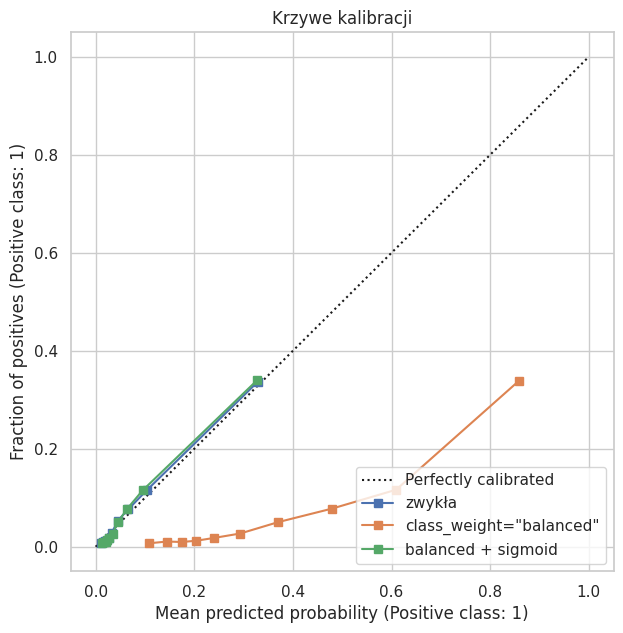

In [9]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import cross_val_predict

def najlepszy_preprocessing():
    return [zamiana_kodow, SimpleImputer(strategy="median", add_indicator=True), Winsoryzacja(0.01), StandardScaler()]

warianty_kal = {
    "zwykła": make_pipeline(*najlepszy_preprocessing(), LR()),
    'class_weight="balanced"': make_pipeline(*najlepszy_preprocessing(), LR(class_weight="balanced")),
    "balanced + sigmoid": CalibratedClassifierCV(make_pipeline(*najlepszy_preprocessing(), LR(class_weight="balanced")),
                                                 method="sigmoid", cv=5),
}
fig, ax = plt.subplots(figsize=(7, 7))
for nazwa, model in warianty_kal.items():
    zapisz(f"kalibracja: {nazwa}", model, "")
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{nazwa:<25} średnie p = {p.mean():.3f}   (odsetek defaultów: {y.mean():.3f})")
    CalibrationDisplay.from_predictions(y, p, n_bins=10, strategy="quantile", ax=ax, name=nazwa)
ax.set_title("Krzywe kalibracji"); plt.show()

**Komentarz:** `class_weight="balanced"` ma prawie ten sam ranking (PR-AUC, ROC-AUC), ale przewiduje średnio ok. **35%** defaultów przy prawdziwych ok. 6.7% — Brier jest dużo gorszy. Kalibracja sigmoidą przywraca średnie p i Briera do poziomu zwykłej regresji, nie psując rankingu.

💬 *Odpowiedź:* do PD bank użyje **zwykłej regresji logistycznej** albo wariantu **skalibrowanego** — oba dają wiarygodne p. Model `balanced` bez kalibracji zawyżyłby oczekiwane straty kilkukrotnie (np. odmawiałby kredytów dobrym klientom). 

## Krok 7: Finał — dziennik i wnioski (~4 min)

1. Wyświetlcie cały dziennik, posortowany po PR-AUC.
2. Wybierzcie **jeden** model, który polecacie bankowi, i uzasadnijcie wybór w 3 zdaniach: (a) który krok dał najwięcej, (b) co **nie** pomogło, (c) dlaczego ten model nadaje się do PD.
3. Sprawdźcie, że Wasz model przyjmuje **surowe dane**.

In [10]:
display(pd.DataFrame(dziennik).set_index("wariant").sort_values("PR-AUC", ascending=False).round(4))

model_finalny = make_pipeline(*najlepszy_preprocessing(), LR()).fit(X, y)
surowe = df_pelny.drop(columns=TARGET).sample(5, random_state=0)
print("PD dla 5 surowych klientów:", model_finalny.predict_proba(surowe)[:, 1].round(3))

,PR-AUC,PR-AUC std,ROC-AUC,Brier,uwagi
wariant,,,,,
[kody+winsor] KNN,0.3565,0.0145,0.8424,0.0517,wolny
"kalibracja: class_weight=""balanced""",0.3565,0.0147,0.8443,0.1506,
kalibracja: balanced + sigmoid,0.3559,0.0153,0.8445,0.0518,
[kody+winsor] Iterative,0.3557,0.0149,0.8423,0.0517,
kody + wskaźnik + winsoryzacja,0.3542,0.0145,0.8411,0.0518,najlepsze połączenie
kalibracja: zwykła,0.3542,0.0145,0.8411,0.0518,
[kody+winsor] mediana,0.3539,0.0147,0.8415,0.0518,baza kroku 5
winsoryzacja 1%,0.3519,0.0164,0.8417,0.0518,
kody 96/98 -> brak + wskaźnik,0.3332,0.0114,0.8023,0.0535,sam kod niesie informację


PD dla 5 surowych klientów: [0.018 0.099 0.032 0.036 0.063]


✍️ **Przykładowe wnioski:**

*(a)* Najwięcej dała naprawa danych: zamiana kodów 96/98 na braki ze wskaźnikiem i winsoryzacja skrajnych wartości — PR-AUC z ok. 0.23 do ok. 0.35, kilkanaście razy więcej niż szum między foldami.

*(b)* Wymyślniejsza imputacja (KNN, Iterative) dała różnice rzędu tysięcznych — w praktyce bez znaczenia; `class_weight="balanced"` nie poprawił rankingu, a zepsuł kalibrację.

*(c)* Do PD polecamy regresję logistyczną bez wag na pipeline'ie „kody → mediana + wskaźnik → winsoryzacja → skalowanie”: ma PR-AUC w granicach szumu od najlepszego wariantu (różnica ok. 0.002 przy odchyleniu ok. 0.015), dobrze skalibrowane p (Brier jak najlepszy) i tylko kilkanaście interpretowalnych cech.